<a href="https://colab.research.google.com/github/AnshG-19/Blackhole_simulator_rayTracing/blob/main/notebooks/03_schwarzschild_geodesics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Black Hole Simulator — Schwarzschild Geodesics

## Objectives
- Understand the path of light in Schwarzschild spacetime
- Compare captured and escaping light rays
- Explore the critical impact parameter
- Visualize several trajectories


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.integrate import solve_ivp

print("Schwarzschild geodesics notebook initialized.")

Schwarzschild geodesics notebook initialized.


Define the black hole
We'll use geometric units, \(G=c=M=1\).

In [2]:
M = 1.0

r_s = 2 * M
r_ph = 3 * M
b_critical = 3 * np.sqrt(3) * M

print("Event horizon radius:", r_s)
print("Photon sphere radius:", r_ph)
print("Critical impact parameter:", b_critical)

Event horizon radius: 2.0
Photon sphere radius: 3.0
Critical impact parameter: 5.196152422706632


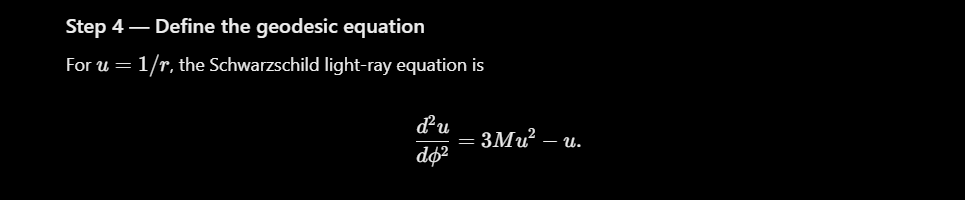

In [3]:
def light_ray_equations(phi, state):
    u, v = state

    du_dphi = v
    dv_dphi = 3 * M * u**2 - u

    return [du_dphi, dv_dphi]

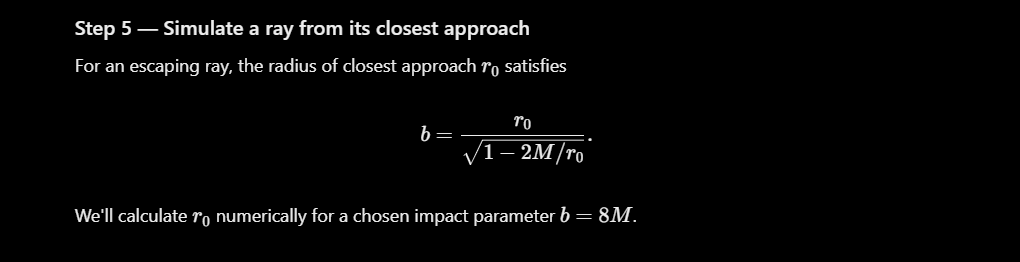

In [4]:
from scipy.optimize import brentq

b = 8.0

def closest_approach_equation(r):
    return r**3 - b**2 * r + 2 * M * b**2

r_min = brentq(
    closest_approach_equation,
    r_ph + 1e-6,
    b
)

print("Impact parameter:", b)
print("Closest approach:", r_min)

Impact parameter: 8.0
Closest approach: 6.700523482266461


Integrate the outgoing ray
At closest approach, \(du/d\phi=0\). We'll start there and integrate outward.

In [5]:
def escaped_ray(b, angle_end=2.5):
    def closest_equation(r):
        return r**3 - b**2 * r + 2 * M * b**2

    r0 = brentq(closest_equation, r_ph + 1e-6, b)

    initial_state = [1 / r0, 0.0]
    angles = np.linspace(0, angle_end, 1200)

    solution = solve_ivp(
        light_ray_equations,
        (0, angle_end),
        initial_state,
        t_eval=angles,
        rtol=1e-9,
        atol=1e-11
    )

    radii = 1 / solution.y[0]

    return angles, radii

Plot the trajectory

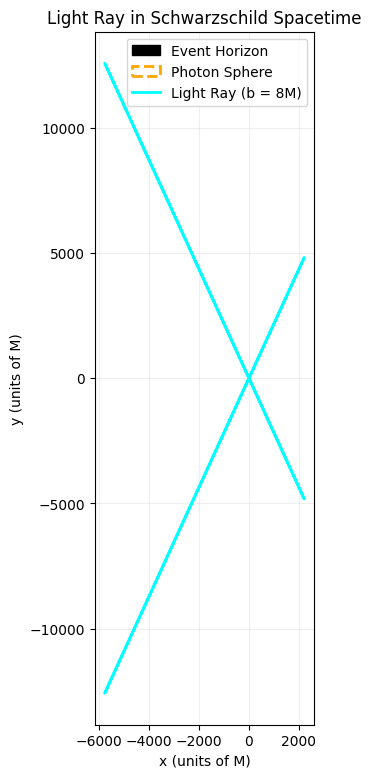

In [6]:
angles, radii = escaped_ray(8.0)

# Reflect around the point of closest approach
angles_full = np.concatenate((-angles[:0:-1], angles))
radii_full = np.concatenate((radii[:0:-1], radii))

x = radii_full * np.cos(angles_full)
y = radii_full * np.sin(angles_full)

fig, ax = plt.subplots(figsize=(9, 9))

ax.add_patch(Circle((0, 0), r_s, color="black",
                    label="Event Horizon"))

ax.add_patch(Circle((0, 0), r_ph, fill=False,
                    linestyle="--", color="orange",
                    linewidth=2, label="Photon Sphere"))

ax.plot(x, y, color="cyan", linewidth=2,
        label="Light Ray (b = 8M)")

ax.set_aspect("equal")
ax.set_xlabel("x (units of M)")
ax.set_ylabel("y (units of M)")
ax.set_title("Light Ray in Schwarzschild Spacetime")
ax.grid(alpha=0.2)
ax.legend()

plt.show()

Compare different impact parameters
Now we'll plot several escaping rays. Larger impact parameters generally mean the light passes farther from the black hole and bends less.

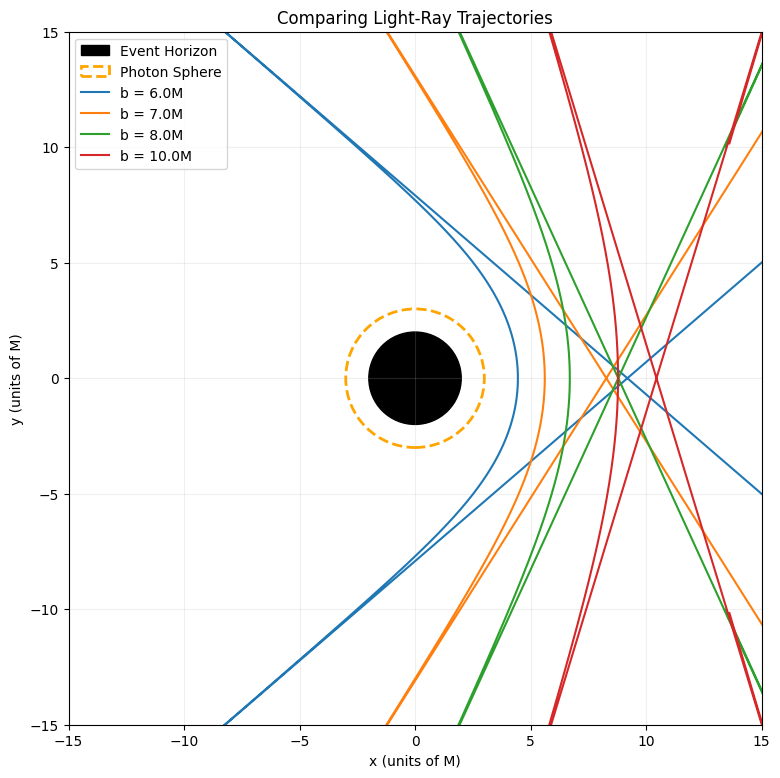

In [7]:
impact_parameters = [6.0, 7.0, 8.0, 10.0]

fig, ax = plt.subplots(figsize=(9, 9))

ax.add_patch(Circle((0, 0), r_s, color="black",
                    label="Event Horizon"))

ax.add_patch(Circle((0, 0), r_ph, fill=False,
                    linestyle="--", color="orange",
                    linewidth=2, label="Photon Sphere"))

for b in impact_parameters:
    angles, radii = escaped_ray(b)

    angles_full = np.concatenate((-angles[:0:-1], angles))
    radii_full = np.concatenate((radii[:0:-1], radii))

    x = radii_full * np.cos(angles_full)
    y = radii_full * np.sin(angles_full)

    ax.plot(x, y, linewidth=1.5, label=f"b = {b}M")

ax.set_aspect("equal")
ax.set_xlim(-15, 15)
ax.set_ylim(-15, 15)
ax.set_xlabel("x (units of M)")
ax.set_ylabel("y (units of M)")
ax.set_title("Comparing Light-Ray Trajectories")
ax.grid(alpha=0.2)
ax.legend()

plt.show()